# 01 · 로봇을 움직인다는 것 — 상태, 입력, 모델, rollout

> 입력(가속도)을 정해 주면 모델로 미래 위치를 미리 계산할 수 있다. MPC와 MPPI는 모두 이 "미리 계산해 보기"에서 출발한다.

**지금 위치**

**01 상태·입력·모델** → 02 비용 → 03 최적화 → 04 MPC → 05~07 MPPI → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. 상태·입력·모델이 각각 무엇인지 구분해서 말할 수 있다.
2. 입력열을 넣어 미래 상태열을 계산(rollout)하는 코드를 직접 쓸 수 있다.
3. 후보 입력열 수백 개를 배열 하나로 한 번에 rollout할 수 있다.

**필요한 것:** 위치·속도·가속도의 관계(고등학교 물리), 파이썬과 numpy 기초 · **예상 시간:** 30분

## 0. 큰 그림 — 이 시리즈가 풀려는 문제

로봇팔을 A에서 B로 옮기려 한다. 그런데 가는 길 앞에 사람 손이 있다. 로봇은 매 순간(1초에 60번) **"지금 어떤 명령을 줄까?"** 를 정해야 한다.

이 시리즈에서 배우는 방법은 사람이 길을 건널 때와 비슷하다.

```text
① 머릿속으로 여러 움직임을 미리 상상한다           ← 01 (이 노트)
② 각 움직임에 점수를 매긴다 (빠른가? 부딪히나?)    ← 02
③ 점수가 가장 좋은 움직임을 고른다                 ← 03, 05~07
④ 그 움직임의 첫 발만 내딛고, 다시 ①로 돌아간다    ← 04
```

이 반복이 **MPC**(Model Predictive Control, 모델 예측 제어)이고, ③을 "후보를 많이 뽑아 보고 좋은 것에 가중치를 주는" 방식으로 하는 것이 **MPPI**다. 둘 다 ①이 없으면 시작할 수 없다. 이 노트는 ①, 즉 **미래를 미리 계산하는 법**을 다룬다.

처음부터 로봇팔로 시작하면 복잡하니, 레일 위를 앞뒤로만 움직이는 **카트 하나**로 시작한다.

In [1]:
import time
import numpy as np
from common import setup_plot
plt = setup_plot()

## 1. 상태 — 미래를 계산하려면 무엇을 알아야 하나

### 문제
카트가 지금 위치 0 m에 있다. 1초 뒤에는 어디에 있을까?

위치만으로는 답할 수 없다. 카트가 멈춰 있었는지 달리고 있었는지에 따라 답이 달라지기 때문이다.

### 아이디어
같은 위치 0 m에서 출발해도, 속도가 0인 카트는 제자리에 있고 속도가 1 m/s인 카트는 1초 뒤 1 m 앞에 있다. 미래를 계산하려면 **위치와 속도를 함께** 알아야 한다.

이렇게 "미래를 계산하는 데 필요한 지금 정보의 묶음"을 **상태**(state)라고 부른다. 카트의 상태는 $x = (p, v)$, 즉 위치 $p$와 속도 $v$다.

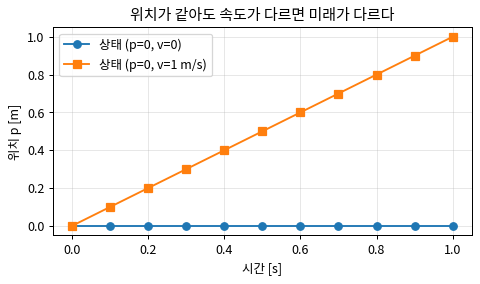

In [2]:
t = np.linspace(0, 1, 11)                  # 0~1초
p_stopped = 0.0 + 0.0 * t                  # p = p0 + v0 * t  (가속 없음)
p_moving = 0.0 + 1.0 * t

plt.figure(figsize=(6, 3))
plt.plot(t, p_stopped, 'o-', label='상태 (p=0, v=0)')
plt.plot(t, p_moving, 's-', label='상태 (p=0, v=1 m/s)')
plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend()
plt.title('위치가 같아도 속도가 다르면 미래가 다르다')
plt.show()

**한 문장으로:** 상태에 속도가 꼭 들어가야 하는 이유를 자기 말로 설명해 보자.

## 2. 입력 — 우리가 정할 수 있는 것

### 문제
카트를 1 m 앞에 세우고 싶다. 우리가 직접 바꿀 수 있는 것은 무엇일까?

위치를 순간이동시킬 수는 없다. 속도도 한순간에 바꿀 수 없다. 모터가 할 수 있는 일은 **힘을 주는 것**이고, 힘은 **가속도**를 만든다.

### 아이디어
그래서 매 순간 우리가 정하는 값, 즉 **입력**(control input)은 가속도 $u$ [m/s²]다.
- $u > 0$: 앞으로 가속한다.
- $u < 0$: 뒤로 가속한다. 앞으로 가던 중이면 감속이 된다.
- $u = 0$: 지금 속도를 그대로 유지한다.

| 구분 | 카트 | 누가 정하나 |
|---|---|---|
| 상태 $x=(p, v)$ | 위치, 속도 | 물리 법칙에 따라 정해진다 |
| 입력 $u$ | 가속도 | **우리가 정한다** (제어기의 출력) |

제어(control)란 결국 "상태를 보고 입력을 정하는 일"이다.

## 3. 모델 — 입력을 주면 다음 상태가 어떻게 되나

### 문제
지금 상태 $(p, v)$에서 가속도 $u$를 짧은 시간 $\Delta t$ 동안 주면, 다음 상태는 어떻게 될까? 이 규칙을 알아야 컴퓨터가 미래를 계산할 수 있다.

### 아이디어
가속도가 $\Delta t$ 동안 일정하다고 보면, 고등학교 등가속도 운동 공식 그대로다.

$$
v_{\text{next}} = v + u\,\Delta t, \qquad p_{\text{next}} = p + v\,\Delta t + \tfrac12 u\,\Delta t^2
$$

말로 하면, 속도는 가속도만큼 늘고, 위치는 원래 속도로 간 거리에 가속도로 더 간 거리를 더한 만큼 바뀐다.

이처럼 "지금 상태 + 입력 → 다음 상태"를 계산하는 규칙을 **모델**(model)이라고 한다.

**숫자로 확인:** $p=0,\ v=0,\ u=2,\ \Delta t=0.1$이면
- $v_{\text{next}} = 0 + 2\times0.1 = 0.2$ m/s
- $p_{\text{next}} = 0 + 0 + \tfrac12\times2\times0.01 = 0.01$ m

**예측해 보기:** 아래 코드는 위 공식을 그대로 옮긴 것이다. 출력이 `[0.01 0.2]`가 될지 실행 전에 확인해 보자.

In [3]:
DT = 0.1   # 시간 간격 Δt [s]

def cart_step(x, u, dt=DT):
    # 상태 x = [p, v], 입력 u(가속도) -> 다음 상태
    p, v = x[..., 0], x[..., 1]
    p_next = p + v * dt + 0.5 * u * dt ** 2
    v_next = v + u * dt
    return np.stack([p_next, v_next], axis=-1)

x0 = np.array([0.0, 0.0])
print(cart_step(x0, 2.0))

[0.01 0.2 ]


**결과 해석:** 손으로 계산한 값과 같다. `x[..., 0]`처럼 `...`을 쓴 이유는 5절에서 상태를 여러 개 한꺼번에 넣기 위해서다. 지금은 `x[0]`과 같다고 보면 된다.

**직접 해보기:** `cart_step(np.array([0.0, 1.0]), 0.0)`의 결과를 먼저 손으로 계산한 뒤 실행해 보자.
<details><summary>예상 결과</summary>

속도 1로 0.1초 가면 위치 0.1, 가속도가 0이니 속도는 그대로 1 → `[0.1 1.]`
</details>

## 4. 시뮬레이션과 rollout — 입력을 여러 개 이어 붙이면

### 문제
한 스텝(0.1초) 앞만 알아서는 부족하다. "1초 동안 가속하고 1초 동안 감속하면 어디에 서나?"처럼 **긴 미래**가 궁금하다.

### 아이디어
모델을 여러 번 반복해서 적용하면 된다. 다음 상태를 다시 모델에 넣고, 또 넣는다.

- 미래에 줄 입력들을 순서대로 늘어놓은 것을 **입력열** $U = (u_0, u_1, \dots, u_{T-1})$이라고 한다.
- 입력열을 모델에 차례로 넣어 미래 상태열 $x_0, x_1, \dots, x_T$를 계산하는 일을 **rollout**(미리 굴려 보기)이라고 한다.
- 몇 스텝 앞까지 볼지 정하는 $T$를 **horizon**(예측 구간)이라고 한다. $T$스텝은 $T\cdot\Delta t$초에 해당한다.

입력이 $T$개면 상태는 처음 상태까지 포함해서 $T+1$개다.

**예측해 보기:** 정지 상태에서 1초 동안 $u=+2$로 가속하고, 이어서 1초 동안 $u=-2$로 감속한다. 2초 뒤 카트의 위치와 속도는 얼마일까?

<details><summary>힌트</summary>

처음 1초: 속도 0→2, 위치는 평균 속도 1 × 1초 = 1 m. 다음 1초: 속도 2→0, 평균 속도 1 × 1초 = 1 m 더.
</details>

In [4]:
def cart_rollout(x0, U, dt=DT):
    # 입력열 U[..., T]를 차례로 넣어 상태열 X[..., T+1, 2]를 만든다
    U = np.asarray(U, float)
    x = np.broadcast_to(np.asarray(x0, float), U.shape[:-1] + (2,))
    X = [x]
    for t in range(U.shape[-1]):
        x = cart_step(x, U[..., t], dt)
        X.append(x)
    return np.stack(X, axis=-2)

U = np.array([2.0] * 10 + [-2.0] * 10)       # T = 20 스텝 = 2초
X = cart_rollout(x0, U)
print('입력열 U 모양:', U.shape, '→ 상태열 X 모양:', X.shape)
print('2초 뒤 위치 %.3f m, 속도 %.3f m/s' % (X[-1, 0], X[-1, 1]))

입력열 U 모양: (20,) → 상태열 X 모양: (21, 2)
2초 뒤 위치 2.000 m, 속도 0.000 m/s


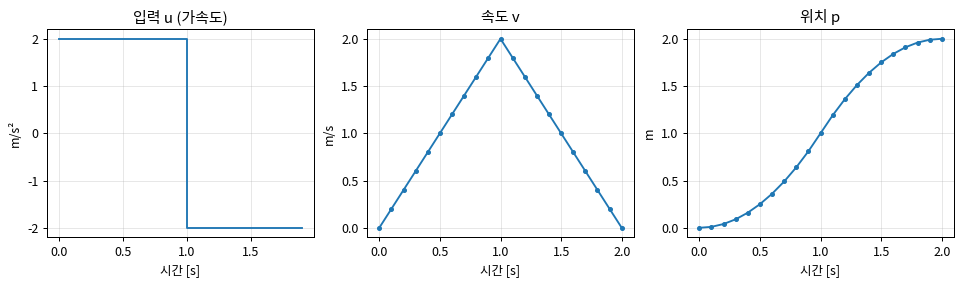

In [5]:
t_u = np.arange(len(U)) * DT
t_x = np.arange(len(X)) * DT
fig, axs = plt.subplots(1, 3, figsize=(13, 3))
axs[0].step(t_u, U, where='post'); axs[0].set_title('입력 u (가속도)'); axs[0].set_ylabel('m/s²')
axs[1].plot(t_x, X[:, 1], '.-'); axs[1].set_title('속도 v'); axs[1].set_ylabel('m/s')
axs[2].plot(t_x, X[:, 0], '.-'); axs[2].set_title('위치 p'); axs[2].set_ylabel('m')
for a in axs: a.set_xlabel('시간 [s]')
plt.show()

**결과 해석:** 예측대로 2초 뒤 위치 2 m, 속도 0이다. 그래프를 보면 입력(가속도)은 계단처럼 바뀌고, 속도는 직선으로, 위치는 곡선으로 바뀐다. 입력이 위치에 **두 번 쌓여서(적분되어)** 나타나기 때문이다. 그래서 가속도를 갑자기 바꿔도 위치는 부드럽게 움직인다.

**직접 해보기:** 카트를 정확히 1 m 지점에 세우는 입력열을 만들어 보자. 위 코드에서 `U`만 바꾸면 된다.
<details><summary>한 가지 답</summary>

가속·감속 크기를 절반으로 줄이면 된다. `U = [1.0]*10 + [-1.0]*10`이면 최고 속도 1 m/s, 위치 0.5+0.5 = 1 m에서 선다. 답은 여러 개다. 03 노트에서는 이런 입력열을 컴퓨터가 직접 찾게 한다.
</details>

**한 문장으로:** rollout이 무엇인지, 입력열과 상태열이라는 말을 넣어 설명해 보자.

## 5. 후보 여러 개를 한 번에 rollout하기

### 문제
뒤에서 배울 MPPI는 매 순간 입력열 후보를 **수백 개** 만들어 각각의 미래를 계산한다(이 프로젝트에서는 400개). 후보마다 따로 for문을 돌리면 느리다.

### 아이디어
후보 $K$개를 행으로 쌓아 배열 하나로 만들고, 같은 계산을 배열 전체에 한 번에 적용한다.

| 배열 | 모양 | 뜻 |
|---|---|---|
| `U` | `[K, T]` | 후보 $K$개, 각각 $T$개 입력 |
| `X` | `[K, T+1, 2]` | 후보마다 $T+1$개 상태, 상태는 (p, v) |

위의 `cart_rollout`은 처음부터 `...`과 `broadcast_to`를 써서 이 경우도 처리하도록 만들어 두었다. 코드를 바꿀 필요가 없다.

U_cands (5, 20) → X_cands (5, 21, 2)


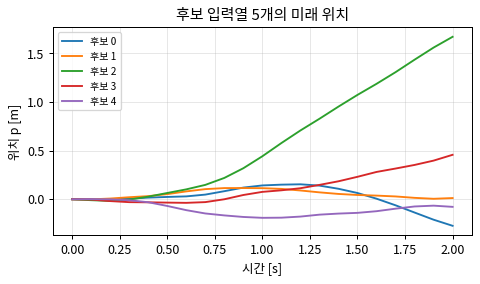

In [6]:
rng = np.random.default_rng(0)
K, T = 5, 20
U_cands = rng.normal(0.0, 1.5, size=(K, T))   # 무작위 후보 입력열 5개
X_cands = cart_rollout(x0, U_cands)
print('U_cands', U_cands.shape, '→ X_cands', X_cands.shape)

plt.figure(figsize=(6, 3))
for k in range(K):
    plt.plot(t_x, X_cands[k, :, 0], label=f'후보 {k}')
plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend(fontsize=8)
plt.title('후보 입력열 5개의 미래 위치')
plt.show()

**예측해 보기:** 후보 400개를 (a) for문으로 하나씩, (b) 배열로 한 번에 rollout하면 속도가 얼마나 차이 날까?

In [7]:
U400 = rng.normal(0.0, 1.5, size=(400, 30))

t0 = time.perf_counter()
X_loop = np.stack([cart_rollout(x0, U400[k]) for k in range(400)])
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
X_batch = cart_rollout(x0, U400)
t_batch = time.perf_counter() - t0

print('결과가 같은가:', np.allclose(X_loop, X_batch))
print('for문 %.1f ms, 배열 %.1f ms → 약 %.0f배' % (1000 * t_loop, 1000 * t_batch, t_loop / t_batch))

결과가 같은가: True
for문 105.2 ms, 배열 0.4 ms → 약 261배


**결과 해석:** 결과는 같고, 배열 방식이 훨씬 빠르다. 실제 로봇에서는 이 계산을 **GPU**에서 한다. 후보 400개 × 30스텝 × 관절 7개를 동시에 계산하기 때문에 1초에 60번 계획을 세울 수 있다. MPPI가 로봇에서 쓰일 수 있는 이유가 여기에 있다.

## 6. 모델은 근사다

### 문제
모델로 계산한 미래가 실제와 똑같을까?

### 아이디어
모델은 현실을 단순화한 것이다. 우리 모델에는 마찰이 없지만 실제 카트에는 마찰이 있다. 같은 입력열을 넣어도 실제 결과는 조금 다르다. 아래에서 "실제 카트"에 속도에 비례하는 마찰을 넣고 비교해 본다.

모델 예측 최종 위치 1.000 m, 실제 최종 위치 0.628 m


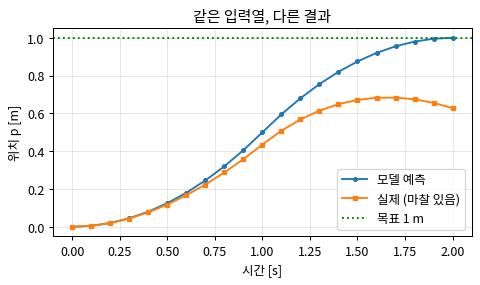

In [8]:
def real_cart_step(x, u, dt=DT, friction=0.5):
    # 실제 카트: 마찰 때문에 실제 가속도 = u - friction * v
    return cart_step(x, u - friction * x[..., 1], dt)

U = np.array([1.0] * 10 + [-1.0] * 10)    # 모델로는 정확히 1 m에서 서는 입력열
X_model = cart_rollout(x0, U)
x = x0.copy(); X_real = [x]
for u in U:
    x = real_cart_step(x, u); X_real.append(x)
X_real = np.array(X_real)

plt.figure(figsize=(6, 3))
plt.plot(t_x, X_model[:, 0], '.-', label='모델 예측')
plt.plot(t_x, X_real[:, 0], 's-', ms=3, label='실제 (마찰 있음)')
plt.axhline(1.0, color='g', ls=':', label='목표 1 m')
plt.xlabel('시간 [s]'); plt.ylabel('위치 p [m]'); plt.legend()
plt.title('같은 입력열, 다른 결과'); plt.show()
print('모델 예측 최종 위치 %.3f m, 실제 최종 위치 %.3f m' % (X_model[-1, 0], X_real[-1, 0]))

**결과 해석:** 모델대로라면 1 m에 서야 하지만, 실제로는 덜 가서 멈춘다(마지막에 속도가 음수가 되어 뒤로 가기도 한다). 미리 계산한 계획을 끝까지 그대로 따르면 오차가 쌓인다.

이 문제를 해결하는 방법이 04 노트의 MPC다. 계획을 한 번 세우고 끝내지 않고, **매 순간 실제 상태를 다시 보고 계획을 새로 세운다.**

## 핵심 정리

- **상태** $x=(p,v)$: 미래를 계산하는 데 필요한 지금 정보. 위치만으로는 부족하다.
- **입력** $u$: 우리가 정하는 값. 여기서는 가속도다.
- **모델**: 상태와 입력으로 다음 상태를 계산하는 규칙 (`cart_step`).
- **rollout**: 입력열 $U$를 모델에 차례로 넣어 미래 상태열을 계산하는 일 (`cart_rollout`). horizon $T$는 몇 스텝 앞까지 보는지를 뜻한다.
- 후보 $K$개를 `[K, T]` 배열로 한 번에 rollout할 수 있고, 이것이 MPPI의 계산 방식이다. 모델은 근사라서 실제와 다르다.

`cart_step`, `cart_rollout`은 `course.py`에 같은 코드로 저장해 두었다. 다음 노트부터는 `from course import cart_rollout`으로 불러 쓴다.

## 확인 문제

<details><summary>1. 상태가 (p, v)인데 입력 u가 상태에 들어가지 않는 이유는?</summary>

상태는 물리적으로 정해지는 "지금의 모습"이고, 입력은 우리가 매 순간 새로 고르는 값이다. 다음 상태는 지금 상태와 지금 입력으로 계산된다.
</details>

<details><summary>2. Δt=0.1 s, T=30이면 rollout은 몇 초 앞까지 계산하는가? 상태는 몇 개 나오는가?</summary>

30 × 0.1 = 3초 앞까지. 상태는 처음 상태를 포함해 31개.
</details>

<details><summary>3. 후보 400개, T=30인 1D 카트 입력 배열의 모양은? 관절이 7개인 로봇팔이라면?</summary>

카트: `[400, 30]`. 로봇팔: 관절마다 가속도가 하나씩 있으므로 `[400, 30, 7]`.
</details>

<details><summary>4. u=0을 계속 주면 카트는 멈추는가?</summary>

아니다. 가속도가 0이면 지금 속도를 유지한다. 멈추려면 속도 반대 방향의 가속도를 줘야 한다.
</details>

## 실제 프로젝트에서는

이 노트의 개념이 franka-depth-mppi에서는 이렇게 쓰인다.

| 이 노트 | 프로젝트 (Franka 로봇팔 + cuRobo) |
|---|---|
| 상태 (p, v) | 관절 7개의 각도와 각속도 |
| 입력 u (가속도) | 관절 7개의 각가속도. cuRobo 설정 `control_space: 'ACCELERATION'` |
| 모델 `cart_step` | cuRobo가 가속도를 적분해 관절 상태를 계산 (질량·관성은 쓰지 않는다) |
| rollout `[K, T]` | `[400, 30, 7]` 가속도 후보 → 미래 관절 상태 (GPU) |
| 실제 카트(마찰) | Isaac Sim 물리 시뮬레이션의 Franka. 모델과 다르게 움직인다 |

09 노트에서 cuRobo로 이 모양들을 직접 확인한다.

## 다음 노트

[02 · 좋은 움직임을 숫자로](02_cost_function.ipynb): 이제 후보들의 미래를 계산할 수 있다. 그런데 어느 후보가 "좋은" 것일까? 컴퓨터가 고를 수 있도록 좋음을 숫자(비용)로 바꾸는 법을 배운다.